# Conflicto de prior como control negativo

**Nivel 3 — Crítica de investigación**  
**Prerrequisitos:** niveles 1–2 y fundamentos de inversión; 35 min.

## Objetivos

Siga la evidencia desde el contrato fuente hasta el resultado. Declare unidades y supuestos, reproduzca el cálculo e identifique qué inferencia no respalda la evidencia.

## Preparación

Usa módulos y registros versionados desde la raíz descubierta; no descarga ni modifica fuentes. Instale versiones exactas: `pip install numpy==2.2.6 matplotlib==3.10.8`

## Datos

Ambos modelos 3D son sintéticos y sus recibos guardan coordenadas y métricas por método.

## Método

`JOINT_CONFLICT` es control negativo sintético diseñado para violar estructura común. Compare razones RMSE conjunta/independiente por propiedad en ambos casos; sobre uno significa peor recuperación. Revise también WRMS y gradiente cruzado: reducir objetivo del optimizador no equivale a recuperar verdad. El método conjunto es creíble cuando datos complementarios apoyan el prior, con unidades/escalas, baseline independiente, predicciones retenidas, sensibilidad a ruido/cobertura y control de conflicto. Los casos heredan generador, malla y solver; no prueban transferencia a campo, resolución de celdas sin muestreo ni superioridad universal. El control es valioso si muestra cuándo el acoplamiento engaña.

Los operadores tienen unidades, cobertura y espacios nulos diferentes. El término cruzado depende de discretización y escala; gradientes paralelos no implican amplitudes iguales ni geología compartida siempre. Compare predicciones de ambos levantamientos además del error contra verdad. Revise unidades y máscaras antes de interpretar razones pequeñas.

## Estado del arte

El estado del arte no es una tabla de posiciones: separe formulación publicada, implementación del producto y evidencia versionada. Una afirmación de avance requiere dominios retenidos independientes, incertidumbre calibrada y réplica.

## Resultados

Lea ejes físicos y unidades; distinga ajuste, error contra verdad sintética y acuerdo con etiquetas humanas. El recálculo debe concordar con el recibo. Un modelo graficado no demuestra unicidad, transferencia a campo ni resolución.

### Diagnostic 1

Inspeccione el recibo y procedencia del caso.

In [1]:
from pathlib import Path
from importlib.metadata import version
print("Runtime versions:", {name: version(name) for name in ['numpy', 'matplotlib']})
import numpy as np
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/"data").is_dir() and (p/"data-pipeline").is_dir())
# Read shared-structure and prior-conflict controls and their saved method metrics.
import json
from pathlib import Path
cases={n:json.loads((root/f"data/derived/v2/{n}/regularization.json").read_text(encoding="utf-8")) for n in ("JOINT_SHARED","JOINT_CONFLICT")}
for n,d in cases.items():
 m=d["methods"]; a=m["joint-uncoupled"]["metrics"]; j=m["joint"]["metrics"]; print(n,"density ratio",j["model_rmse"]/a["model_rmse"],"magnetic ratio",j["magnetic_model_rmse"]/a["magnetic_model_rmse"],"joint WRMS",j["wrms"],j["magnetic_wrms"])

Runtime versions: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
JOINT_SHARED density ratio 1.0041520681109284 magnetic ratio 0.9976694970607447 joint WRMS 1.088985 1.005056
JOINT_CONFLICT density ratio 1.0000877810389763 magnetic ratio 0.9993365874157223 joint WRMS 1.041742 1.057214


### Diagnostic 2

Calcule la comparación y grafíquela con unidades físicas.

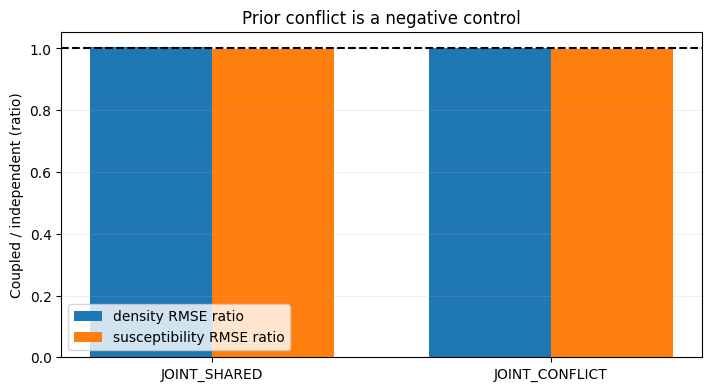

{'JOINT_SHARED': [1.0041520681109284, 0.9976694970607447], 'JOINT_CONFLICT': [1.0000877810389763, 0.9993365874157223]}


In [2]:
import numpy as np
import matplotlib.pyplot as plt
# Ratios above one denote worse coupled model RMSE; compare both properties across controls.
import matplotlib.pyplot as plt
names=list(cases); vals=[]
for n in names:
 m=cases[n]["methods"]; a=m["joint-uncoupled"]["metrics"]; j=m["joint"]["metrics"]; vals.append([j["model_rmse"]/a["model_rmse"],j["magnetic_model_rmse"]/a["magnetic_model_rmse"]])
v=np.asarray(vals); x=np.arange(2); fig,ax=plt.subplots(figsize=(7,3.8),constrained_layout=True); ax.bar(x-.18,v[:,0],.36,label="density RMSE ratio"); ax.bar(x+.18,v[:,1],.36,label="susceptibility RMSE ratio"); ax.axhline(1,color="black",ls="--"); ax.set(xticks=x,xticklabels=names,ylabel="Coupled / independent (ratio)",title="Prior conflict is a negative control"); ax.legend(); ax.grid(axis="y",alpha=.2); plt.show(); print(dict(zip(names,v.tolist())))

## Resumen

La conclusión depende de geometría, adquisición, ruido, partición, parametrización y derechos de fuente. Conserve negativos y nombre la observación o control siguiente.

## Referencias

- [https://docs.simpeg.xyz/latest/content/user-guide/tutorials/13_joint_inversion/plot_inv_3_cross_gradient_pf.html](https://docs.simpeg.xyz/latest/content/user-guide/tutorials/13_joint_inversion/plot_inv_3_cross_gradient_pf.html)
- [https://www.pygimli.org/user-guide/inversion/](https://www.pygimli.org/user-guide/inversion/)